# Day 2 lecture: Visualising and communicating results

<p class="lead">
A chart is an argument made with shapes and colours. This lecture shows how the eye reads a chart, how charts mislead and how to rebuild them honestly, how to turn findings into a short story for a decision-maker, how to design a dashboard around a few good KPIs, and how marketing teams measure their funnel.
</p>

Open this notebook in JupyterLab from the course folder and run each cell from top to bottom with **Shift + Enter**.

---

## What you will be able to do

1. Choose a chart from the **task** the reader has to do, and explain why position and length beat angle, area and colour.
2. Use **pre-attentive attributes**, **data-ink** and **Gestalt** principles to direct the reader's eye.
3. Choose **categorical**, **sequential** or **diverging** colour, and keep charts readable for colour-blind readers.
4. Spot a **misleading chart** (truncated bars, dual axes, scaled areas, crowded pies) and rebuild it honestly.
5. Turn findings into a story: **audience**, **big idea**, **situation, complication, resolution** and **message titles**.
6. Explain what the **Challenger** O-ring data show when the flights with no damage are included.
7. Lay out a **dashboard** with 3–5 views and KPI tiles, and compute ratio KPIs as a **ratio of sums**.
8. Read a marketing **funnel** and compute conversion rate, **CPA** and **ROAS**; explain segmentation, customer lifetime value and the limits of attribution.

**Reading:** Tableau Software (n.d.), *What is data visualization?*; the course pages [Designing clear visuals](../foundations/visual-design.md) and [Storytelling with data](../foundations/storytelling.md).

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words, alone or with the person next to you.

| Part | Topic |
|---|---|
| 1 | Choose the chart from the task |
| 2 | How accurately we read encodings |
| 3 | Pre-attentive attributes |
| 4 | Data-ink and decluttering |
| 5 | Gestalt: what belongs together |
| 6 | Colour with a job, and accessibility |
| 7 | Honest axes and misleading charts |
| 8 | Message titles, annotation and small multiples |
| 9 | Communicating results: audience, big idea, story |
| 10 | The Challenger case |
| 11 | Dashboards and KPIs |
| 12 | Marketing analytics |

---

## Recap: Day 1

Answer in your own words before we start. We discuss them together.

1. Name the four kinds of analytics and give a one-line example of the **diagnostic** kind.
2. Four datasets share the same means, standard deviations and correlation. What must you still do before you describe them?
3. On Day 1 the average tip was highest on Sunday. What did the diagnostic step show about **why**?
4. What does one row of the tips table represent?

Run the setup cell first. It loads the libraries, sets a clean chart style and reads the two bundled datasets:

| File | One row is | Used for |
|---|---|---|
| `data/tips.csv` | One restaurant bill (one table served), with the tip, in US dollars | Honest axes, Gestalt, KPIs, segmentation |
| `data/mpg.csv` | One car model from the 1970s and early 1980s, with its fuel economy in miles per gallon (mpg) | Chart choice, decluttering, colour, small multiples |

In [1]:
import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"   # context
INK = "#55534e"    # notes and labels
# Okabe-Ito: a palette that stays distinguishable for the common forms of colour blindness
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
DAYS = ["Thur", "Fri", "Sat", "Sun"]   # the restaurant's days, in week order

plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.float_format", "{:,.2f}".format)

tips = pd.read_csv("data/tips.csv")
cars = pd.read_csv("data/mpg.csv")

# Car makers: the first word of the name, with the spelling variants in the file merged.
MAKER_FIXES = {"chevy": "chevrolet", "chevroelt": "chevrolet", "vw": "volkswagen",
               "vokswagen": "volkswagen", "maxda": "mazda", "toyouta": "toyota",
               "mercedes-benz": "mercedes"}
cars["maker"] = cars["name"].str.split().str[0].replace(MAKER_FIXES)

print("Bills:", len(tips), "| car models:", len(cars), "| car makers:", cars["maker"].nunique())

Bills: 244 | car models: 398 | car makers: 30


---

## Part 1: Choose the chart from the task

Do not start from "which chart looks good". Start from **what the reader must do** with the numbers.

| Task | The reader asks | Good first choice | Usually avoid |
|---|---|---|---|
| **Compare** categories | Which is bigger, and by how much? | Sorted bar chart (horizontal when labels are long) | Pie, 3D bars |
| **Composition** | What share does each part make? | Stacked bar, or a bar of shares; a pie only for two or three parts | Pie with many slices |
| **Distribution** | What values are typical, how spread, any outliers? | Histogram, box plot | Bar of the average alone |
| **Relationship** | Do two measures move together? | Scatter plot | Two lines on dual axes |
| **Change over time** | Rising, falling, seasonal? | Line chart, time on the x-axis | Unsorted bars, a pie per year |

Three of these tasks on the tips data, one chart each:

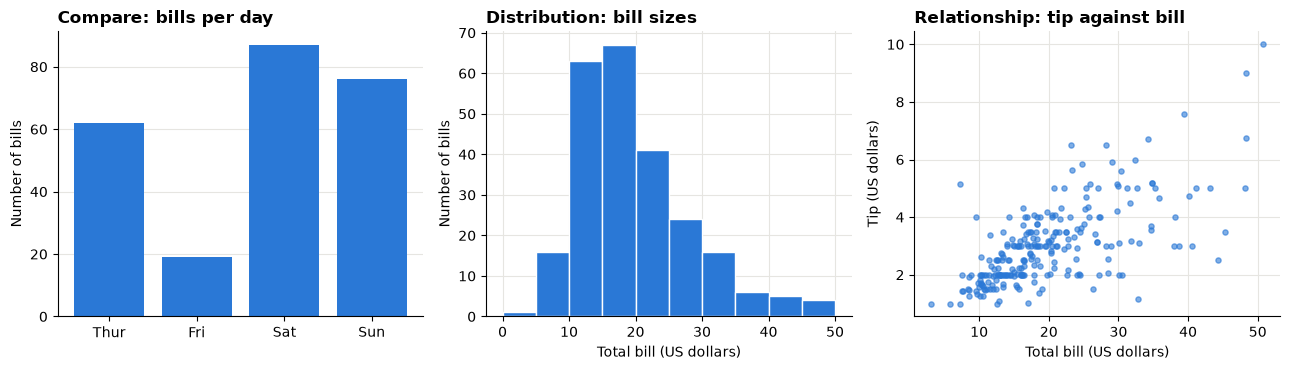

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

bills_per_day = tips["day"].value_counts().reindex(DAYS)
axes[0].bar(bills_per_day.index, bills_per_day, color=BLUE)
axes[0].set_title("Compare: bills per day")
axes[0].set_ylabel("Number of bills")
axes[0].grid(axis="x", visible=False)

axes[1].hist(tips["total_bill"], bins=range(0, 55, 5), color=BLUE, edgecolor="white")
axes[1].set_title("Distribution: bill sizes")
axes[1].set_xlabel("Total bill (US dollars)")
axes[1].set_ylabel("Number of bills")

axes[2].scatter(tips["total_bill"], tips["tip"], s=14, color=BLUE, alpha=0.6)
axes[2].set_title("Relationship: tip against bill")
axes[2].set_xlabel("Total bill (US dollars)")
axes[2].set_ylabel("Tip (US dollars)")

fig.tight_layout()
plt.show()

> **Predict, then reveal**
>
> The next chart shows how many car models in the `mpg` data come from each maker, as a pie. Before you run it, get a pen ready. From the chart alone, write down: (1) which maker is **fifth** largest, and (2) roughly how many times bigger the largest slice is than the **third** largest.

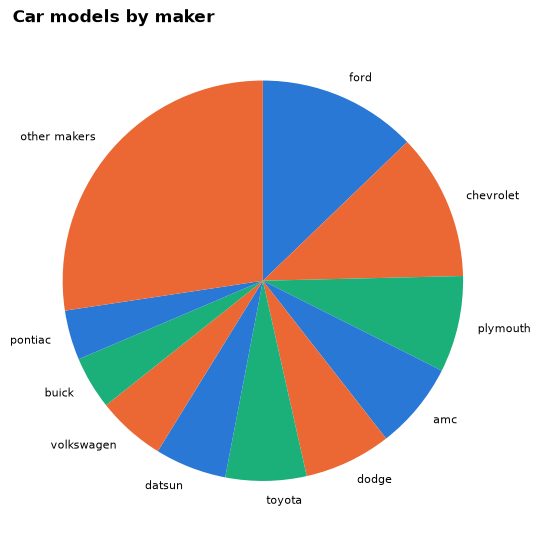

In [3]:
by_maker = cars["maker"].value_counts()
top = by_maker.head(10)
pie_data = pd.concat([top, pd.Series({"other makers": by_maker.iloc[10:].sum()})])

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(pie_data, labels=pie_data.index, startangle=90, counterclock=False, textprops={"fontsize": 8})
ax.set_title("Car models by maker")
plt.show()

Now the same numbers as a sorted bar chart. Check your two answers.

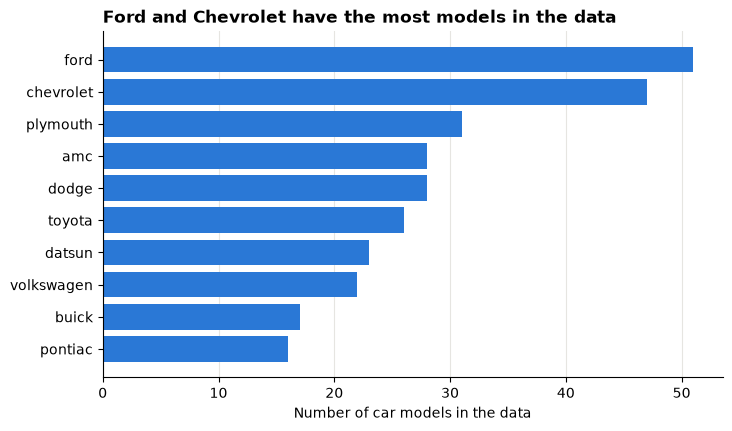

Fifth largest: dodge
Largest divided by third largest: 1.65


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color=BLUE)
ax.grid(axis="y", visible=False)
ax.set_title("Ford and Chevrolet have the most models in the data" if list(top.index[:2]) == ["ford", "chevrolet"]
             else "Car models by maker, ten largest makers")
ax.set_xlabel("Number of car models in the data")
plt.show()

print("Fifth largest:", top.index[4])
print("Largest divided by third largest:", round(top.iloc[0] / top.iloc[2], 2))

With bars, the ranking is the reading order and the size ratio is a comparison of lengths from one baseline. With the pie, you had to compare angles of slices that do not share a starting line, and the "other makers" slice hid 27 makers in one wedge.

> **Check your understanding**
>
> For each request, name the task and a first chart choice:
>
> 1. "How long do our deliveries usually take, and how often are they very late?"
> 2. "Has the share of online sales grown over the last three years?"
> 3. "Do customers who get bigger discounts buy more items?"
> 4. "Which of our 12 warehouses had the highest return rate last quarter?"

---

## Part 2: How accurately we read encodings

An **encoding** is how a number becomes something visible: a position, a length, an angle, an area, a colour. Experiments by William Cleveland and Robert McGill (1984), repeated many times since, found that people judge some encodings much more accurately than others.

| Rank | Encoding | Example |
|---|---|---|
| 1 (most accurate) | **Position on a common scale** | Dots or bar ends against one axis |
| 2 | **Length** | Bars that start at the same baseline |
| 3 | **Angle and slope** | Pie slices, line steepness |
| 4 | **Area** | Bubbles, treemaps |
| 5 (least accurate) | **Colour intensity and hue** | Shaded maps, heatmaps |

Put the most important comparison on **position or length**. Use colour and area for secondary information or for highlighting.

> **Predict, then reveal**
>
> Five made-up values are drawn as pie slices and as bubbles. Rank them from largest to smallest using only these two pictures, and write your ranking down.

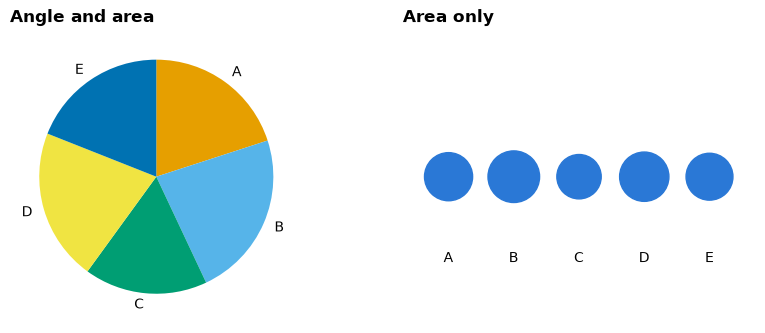

In [5]:
values = pd.Series({"A": 20, "B": 23, "C": 17, "D": 21, "E": 19})  # made-up values

fig, (ax_pie, ax_bubble) = plt.subplots(1, 2, figsize=(10, 3.8))
ax_pie.pie(values, labels=values.index, startangle=90, counterclock=False, colors=OKABE_ITO[:5])
ax_pie.set_title("Angle and area")

ax_bubble.scatter(range(len(values)), [0] * len(values), s=values * 60, color=BLUE)
for i, label in enumerate(values.index):
    ax_bubble.text(i, -0.35, label, ha="center")
ax_bubble.set_xlim(-0.7, 4.7)
ax_bubble.set_ylim(-0.6, 0.6)
ax_bubble.axis("off")
ax_bubble.set_title("Area only")
plt.show()

Now the same five values as bars on a common baseline.

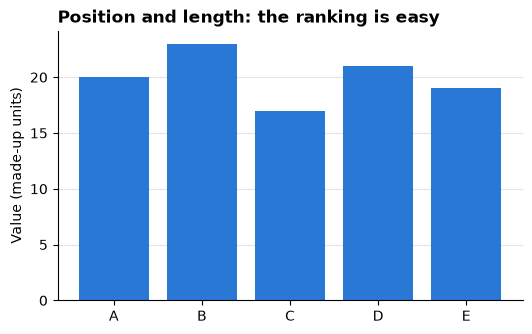

True ranking: B, D, A, E, C


In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(values.index, values, color=BLUE)
ax.grid(axis="x", visible=False)
ax.set_title("Position and length: the ranking is easy")
ax.set_ylabel("Value (made-up units)")
plt.show()

print("True ranking:", ", ".join(values.sort_values(ascending=False).index))

Most people get the slices and bubbles partly wrong when values are close, and nearly everyone gets the bars right. This is the main reason analysts prefer bars and dots.

> **Check your understanding**
>
> A colleague shows a map where each province's profit is shown only by its shade of green. Name one question this map answers badly, and a chart that answers it better.

---

## Part 3: Pre-attentive attributes

Some differences are seen in a fraction of a second, before you consciously search: **colour**, **size**, **position**, **orientation**, **shape**, **enclosure**. They are called **pre-attentive** attributes.

> **Predict, then reveal**
>
> The next cell draws two panels. In each, find the odd one out. Which panel is faster, and why?

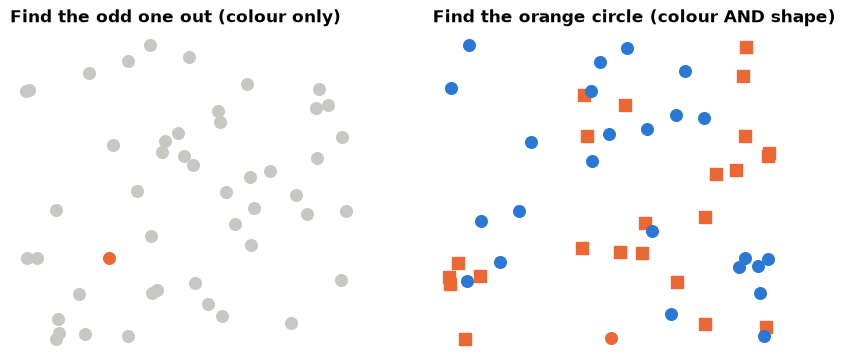

In [7]:
rng = np.random.default_rng(2)  # fixed seed: the made-up dots look the same every run

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
xy = rng.uniform(0, 1, size=(48, 2))
ax1.scatter(xy[1:, 0], xy[1:, 1], s=70, color=GREY)
ax1.scatter(xy[0, 0], xy[0, 1], s=70, color=ORANGE)
ax1.set_title("Find the odd one out (colour only)")

xy2 = rng.uniform(0, 1, size=(48, 2))
half = len(xy2) // 2
ax2.scatter(xy2[1:half, 0], xy2[1:half, 1], s=70, color=ORANGE, marker="s")
ax2.scatter(xy2[half:, 0], xy2[half:, 1], s=70, color=BLUE, marker="o")
ax2.scatter(xy2[0, 0], xy2[0, 1], s=70, color=ORANGE, marker="o")
ax2.set_title("Find the orange circle (colour AND shape)")

for ax in (ax1, ax2):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

On the left the orange dot "pops out" at once. On the right you must scan, because the target differs only by a **combination** of colour and shape, and combinations are not pre-attentive.

**Lessons for charts:**

1. Use **one** pre-attentive attribute to mark what matters, usually one strong colour against grey.
2. If everything is highlighted, nothing is. Five bright colours give the eye five places to look.
3. Do not ask the reader to decode combinations ("orange squares are Saturday dinners").

---

## Part 4: Data-ink and decluttering

Edward Tufte's **data-ink ratio** asks: how much of the ink shows data? Everything else (heavy grids, borders, colours with no meaning, rotated labels) costs the reader attention.

Here is matplotlib's **default** style showing the average fuel economy of each maker with at least ten models. `plt.style.context("default")` switches off our clean style for this one chart.

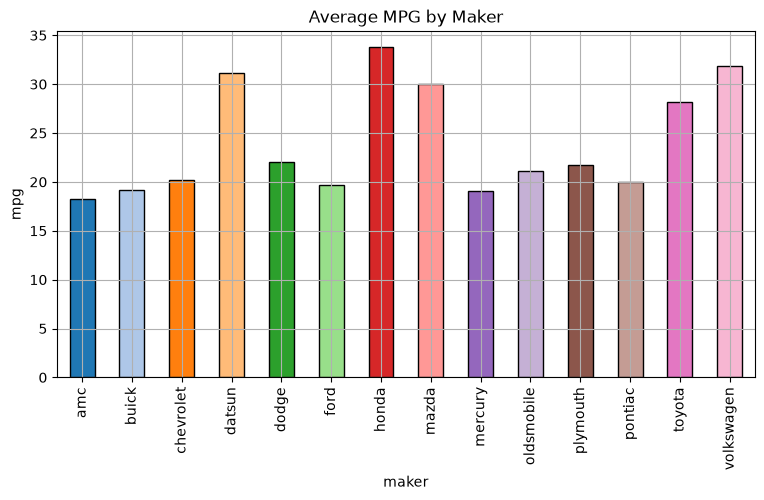

In [8]:
big_makers = by_maker[by_maker >= 10].index
avg_mpg = cars[cars["maker"].isin(big_makers)].groupby("maker")["mpg"].mean()

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    avg_mpg.plot(kind="bar", ax=ax, color=plt.cm.tab20.colors, edgecolor="black")
    ax.grid(True)
    ax.set_title("Average MPG by Maker")
    ax.set_ylabel("mpg")
    plt.show()

> **Predict, then reveal**
>
> List three things on this chart that do **not** help the reader, and one question it makes hard to answer. Then run the next cell.

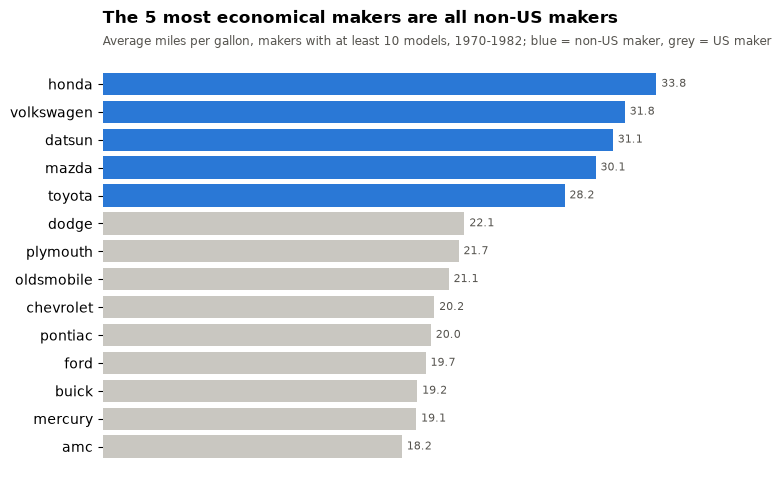

In [9]:
sorted_mpg = avg_mpg.sort_values()
best = sorted_mpg.index[-1]
usa_makers = set(cars.loc[cars["origin"] == "usa", "maker"])
colours = [GREY if maker in usa_makers else BLUE for maker in sorted_mpg.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(sorted_mpg.index, sorted_mpg, color=colours)
for name, value in sorted_mpg.items():
    ax.text(value + 0.3, name, f"{value:.1f}", va="center", fontsize=8, color=INK)
ax.set_xlim(0, sorted_mpg.max() * 1.12)
ax.set_xticks([])
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)

ranked = list(sorted_mpg.index[::-1])   # most economical first
n_foreign_top = next((i for i, m in enumerate(ranked) if m in usa_makers), len(ranked))
ax.set_title(f"The {n_foreign_top} most economical makers are all non-US makers" if n_foreign_top >= 2
             else f"{best} has the highest average fuel economy", pad=22)
ax.text(0, 1.02, "Average miles per gallon, makers with at least 10 models, 1970-1982; blue = non-US maker, grey = US maker",
        transform=ax.transAxes, fontsize=8.5, color=INK)
plt.show()

What changed, and why:

| Change | Principle |
|---|---|
| Sorted by value | The ranking is now the reading order |
| Horizontal bars | Long labels are readable without tilting your head |
| Colour with a meaning (blue = non-US maker), grey for the rest | One pre-attentive attribute, one message |
| Values written on the bars, value axis removed | Exact numbers without tracing a grid |
| The title states the finding; the subtitle states scope and units | The reader knows what to look for and what was counted |

> **Do not overdo it**
>
> Decluttering stops when removing something would lose meaning: units, the period, the scope or a zero line. The aim is clarity, not minimalism.

> **Check your understanding**
>
> The "after" chart removed the value axis. Give one situation where you should **keep** a value axis instead of writing numbers on the bars.

---

## Part 5: Gestalt: what belongs together

Gestalt principles describe how we group what we see. You can use them to decide what the reader compares.

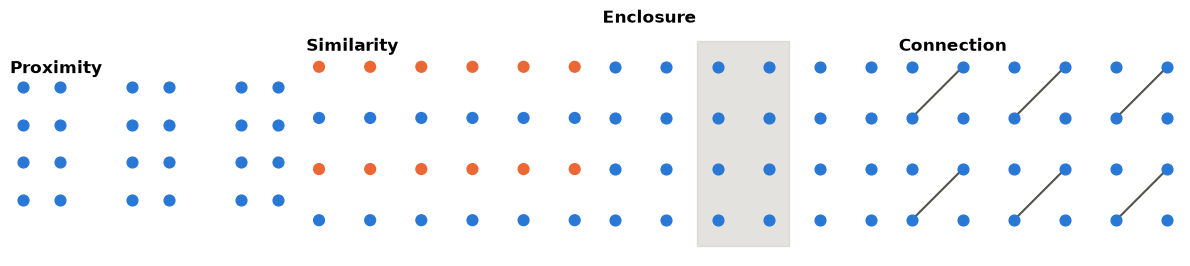

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
gx, gy = np.meshgrid(np.arange(6), np.arange(4))
gx, gy = gx.ravel(), gy.ravel()

axes[0].scatter(gx + (gx // 2) * 0.9, gy, s=60, color=BLUE)   # columns pushed into pairs
axes[0].set_title("Proximity")
axes[1].scatter(gx, gy, s=60, color=[ORANGE if row % 2 else BLUE for row in gy])
axes[1].set_title("Similarity")
axes[2].scatter(gx, gy, s=60, color=BLUE)
axes[2].add_patch(Rectangle((1.6, -0.5), 1.8, 4, color=GREY, alpha=0.5, zorder=0))
axes[2].set_title("Enclosure")
axes[3].scatter(gx, gy, s=60, color=BLUE)
for x0 in (0, 2, 4):
    for y0 in (0, 2):
        axes[3].plot([x0, x0 + 1], [y0, y0 + 1], color=INK, linewidth=1.5, zorder=0)
axes[3].set_title("Connection")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
plt.show()

| Principle | What you saw | Use in charts |
|---|---|---|
| **Proximity** | Pairs of columns | Bars placed close together are compared first |
| **Similarity** | Rows, although spacing is equal | Same colour = same category in every panel |
| **Enclosure** | The boxed columns form a group | Shade a period (a promotion, a holiday) |
| **Connection** | Joined dots read as pairs | Lines join points that belong to one series |

### Proximity decides the comparison

The same numbers, grouped two ways: the tip as a percentage of the bill, for male and female bill payers on each day. The percentage is total tips divided by total bills for each group (a **ratio of sums**, explained in Part 11). Which question does each chart answer easily?

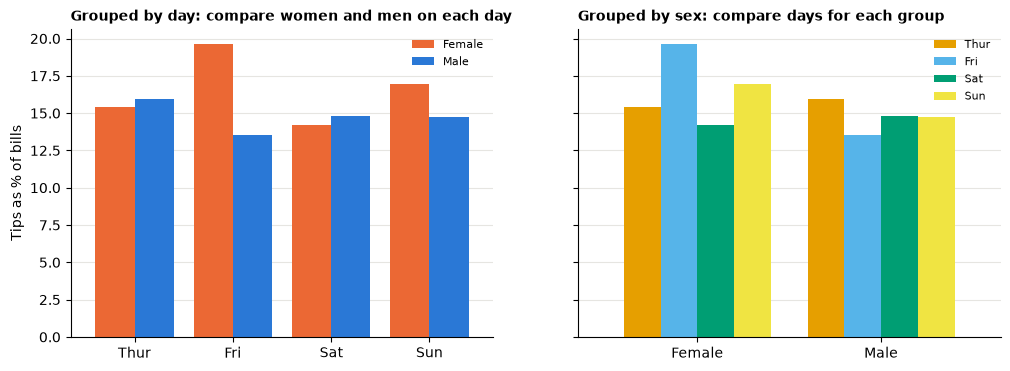

In [11]:
groups = tips.groupby(["day", "sex"])[["tip", "total_bill"]].sum()
tip_pct = (100 * groups["tip"] / groups["total_bill"]).unstack().reindex(DAYS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
tip_pct.plot(kind="bar", ax=ax1, rot=0, color=[ORANGE, BLUE], width=0.8)
ax1.set_title("Grouped by day: compare women and men on each day", fontsize=10)
tip_pct.T.plot(kind="bar", ax=ax2, rot=0, color=OKABE_ITO[:4], width=0.8)
ax2.set_title("Grouped by sex: compare days for each group", fontsize=10)
for ax in (ax1, ax2):
    ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, fontsize=8)
ax1.set_ylabel("Tips as % of bills")
plt.show()

Bars that sit next to each other get compared. Put **next to each other** the things your question compares.

---

## Part 6: Colour with a job, and accessibility

Colour should do one of three jobs. Match the palette to the job.

| Data | Palette type | Example | Rule |
|---|---|---|---|
| **Categories** with no order | Categorical: distinct hues | Regions, channels | At most about six; same category, same colour everywhere |
| **Ordered amounts** from low to high | Sequential: one hue, light to dark | Average mpg by origin and year | Darker = more |
| **Values around a meaningful middle** | Diverging: two hues, neutral centre | Above or below the overall average; profit or loss | The neutral colour sits exactly at the middle value |

The helper below draws a table as a heatmap and writes each value in its cell, in white on dark cells and black on light cells.

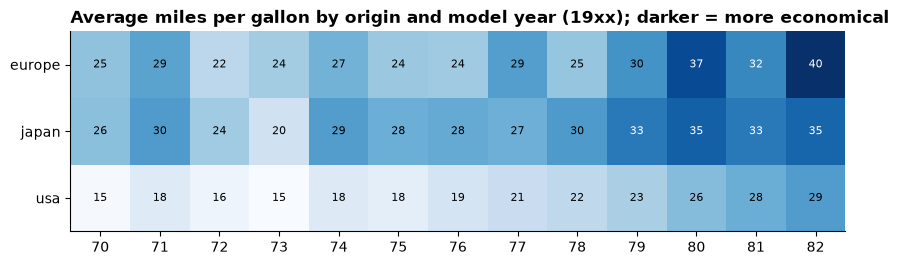

In [12]:
def heatmap(ax, table, cmap, norm=None, fmt="{:.0f}"):
    image = ax.imshow(table.values, cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    for (i, j), value in np.ndenumerate(table.values):
        r, g, b, _ = image.cmap(image.norm(value))
        text_colour = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black"
        ax.text(j, i, fmt.format(value), ha="center", va="center", fontsize=8, color=text_colour)
    return image


mpg_year = cars.pivot_table(index="origin", columns="model_year", values="mpg", aggfunc="mean")

fig, ax = plt.subplots(figsize=(10, 2.6))
heatmap(ax, mpg_year, cmap="Blues")
ax.set_title("Average miles per gallon by origin and model year (19xx); darker = more economical")
plt.show()

> **Predict, then reveal: diverging**
>
> Now the question changes: which cells are **above** the overall average fuel economy, and which are **below**? The next cell subtracts the overall average and draws the result twice, first with a sequential palette and then with a diverging palette centred on zero. In which one can you see the answer at a glance?

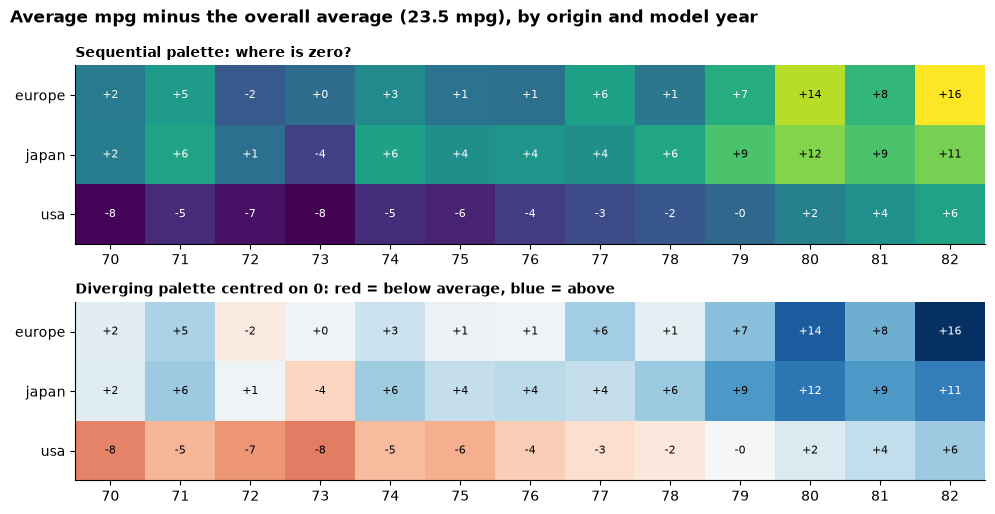

In [13]:
overall = cars["mpg"].mean()
gap = mpg_year - overall
limit = gap.abs().max().max()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.2))
heatmap(ax1, gap, cmap="viridis", fmt="{:+.0f}")
ax1.set_title("Sequential palette: where is zero?", fontsize=10)
heatmap(ax2, gap, cmap="RdBu", norm=TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit), fmt="{:+.0f}")
ax2.set_title("Diverging palette centred on 0: red = below average, blue = above", fontsize=10)
fig.suptitle(f"Average mpg minus the overall average ({overall:.1f} mpg), by origin and model year",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

With the diverging palette, every below-average cell is red and every above-average cell blue, and the palest cells are close to average. The sequential palette hid the most important boundary in the data: zero.

> **Colour-blind safety and accessibility**
>
> About 1 in 12 men and 1 in 200 women have some colour-vision deficiency, most often difficulty telling red from green.
>
> 1. Avoid red against green as the only difference. Red–blue or orange–blue are safer. This course uses blue, orange and aqua, with grey for context.
> 2. Use a tested palette such as Okabe–Ito for categories (`OKABE_ITO` in the setup cell).
> 3. **Never rely on colour alone.** Add labels, positions or text that carry the same meaning, so the chart still works printed in black and white.
> 4. Keep enough contrast between text and background, and font sizes readable from the back of the room.

### Highlight one series, grey the rest

The question decides which line gets the colour. Here: which origin's cars improved fuel economy the most between the first and last model year? The code finds it; the chart puts it in colour and the others in grey.

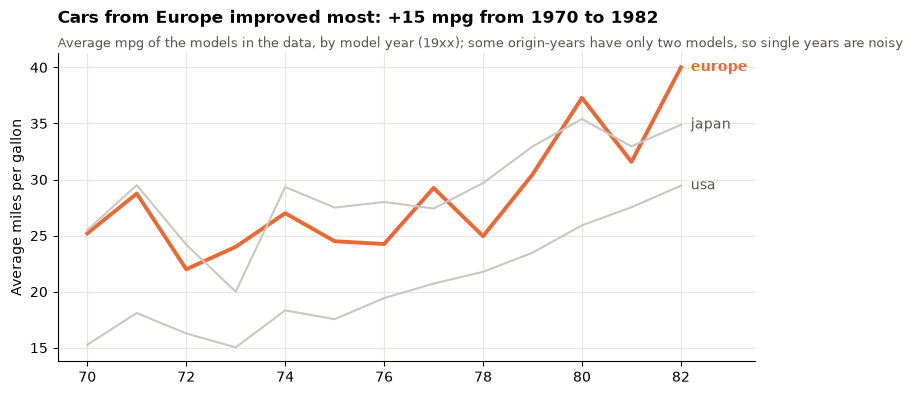

In [14]:
change = (mpg_year.iloc[:, -1] - mpg_year.iloc[:, 0]).sort_values()
focus = change.index[-1]

fig, ax = plt.subplots(figsize=(9, 4))
for origin in mpg_year.index:
    colour, width = (ORANGE, 2.8) if origin == focus else (GREY, 1.5)
    ax.plot(mpg_year.columns, mpg_year.loc[origin], color=colour, linewidth=width)
    ax.text(mpg_year.columns[-1] + 0.2, mpg_year.loc[origin].iloc[-1], origin,
            color=colour if origin == focus else INK, va="center",
            fontweight="bold" if origin == focus else "normal")
ax.set_xlim(right=mpg_year.columns[-1] + 1.5)
ax.set_title(f"Cars from {focus.title()} improved most: {change[focus]:+.0f} mpg from 1970 to 1982", pad=22)
ax.text(0, 1.02, "Average mpg of the models in the data, by model year (19xx); some origin-years have only two models, so single years are noisy",
        transform=ax.transAxes, fontsize=9, color=INK)
ax.set_ylabel("Average miles per gallon")
plt.show()

> **Check your understanding**
>
> Which palette type (categorical, sequential or diverging) fits each case, and why?
>
> 1. Customer satisfaction score from 1 to 10 for each store.
> 2. Change in headcount versus last year, by department (some up, some down).
> 3. Five product lines on one line chart.

---

## Part 7: Honest axes and misleading charts

A chart can be built entirely from true numbers and still leave a false impression. Each example below shows a **before** that misleads and an **after** that rebuilds it honestly.

### Misleading chart 1: the truncated bar axis

A bar's **length** is the encoding. If the axis does not start at zero, the lengths lie. The tip as a percentage of the bill, by day (total tips ÷ total bills):

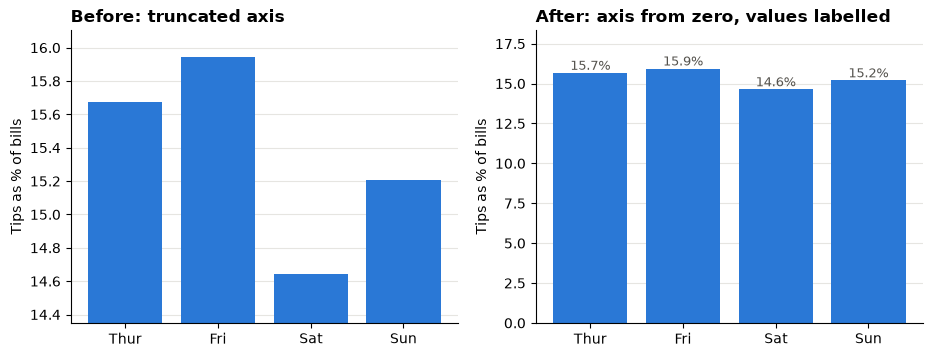

Highest day divided by lowest day: 1.09


In [15]:
day_totals = tips.groupby("day")[["tip", "total_bill"]].sum().reindex(DAYS)
day_pct = 100 * day_totals["tip"] / day_totals["total_bill"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(day_pct.index, day_pct, color=BLUE)
ax1.set_ylim(day_pct.min() * 0.98, day_pct.max() * 1.01)
ax1.set_title("Before: truncated axis")
ax2.bar(day_pct.index, day_pct, color=BLUE)
for i, value in enumerate(day_pct):
    ax2.text(i, value, f"{value:.1f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax2.set_ylim(0, day_pct.max() * 1.15)
ax2.set_title("After: axis from zero, values labelled")
for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("Tips as % of bills")
plt.show()

print("Highest day divided by lowest day:", round(day_pct.max() / day_pct.min(), 2))

On the left, one day looks several times more generous than another. The printed ratio shows the true difference.

**Lines are different.** A line's message is its **shape** (rising, falling, seasonal), read from position, not length. A line chart may zoom in to the range of the data, as long as the axis is labelled. The rule: **bars from zero; lines may zoom, with labels**.

### Misleading chart 2: dual axes

A dual-axis chart puts two measures on one picture, each with its own scale. Whoever draws it chooses both scales, and with them the "story". Two made-up monthly series:

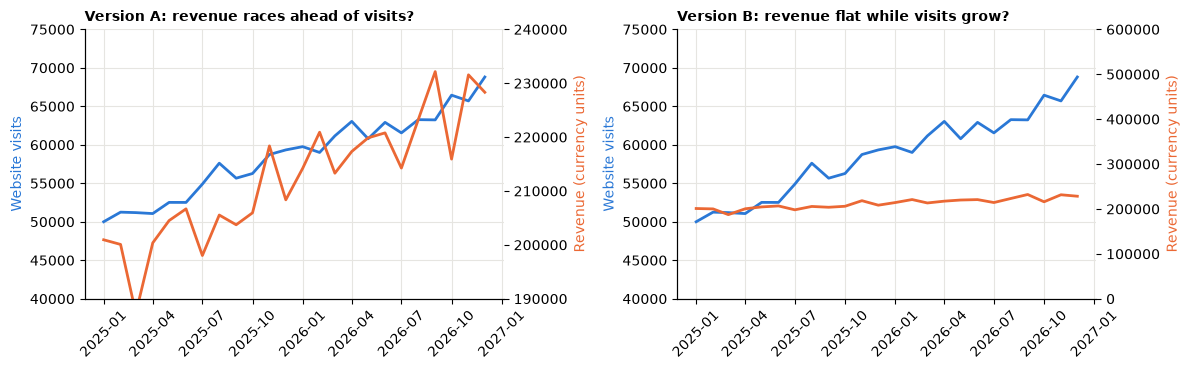

In [16]:
rng = np.random.default_rng(7)  # fixed seed
months = pd.date_range("2025-01-01", periods=24, freq="MS")
visits = pd.Series(50_000 + np.arange(24) * 800 + rng.normal(0, 1_500, 24), index=months)
revenue = pd.Series(200_000 + np.arange(24) * 1_200 + rng.normal(0, 6_000, 24), index=months)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
right_limits = [(190_000, 240_000), (0, 600_000)]
titles = ["Version A: revenue races ahead of visits?", "Version B: revenue flat while visits grow?"]
for ax, (low, high), title in zip(axes, right_limits, titles):
    ax.plot(visits, color=BLUE, linewidth=2)
    ax.set_ylim(40_000, 75_000)
    ax.set_ylabel("Website visits", color=BLUE)
    right = ax.twinx()
    right.plot(revenue, color=ORANGE, linewidth=2)
    right.set_ylim(low, high)
    right.set_ylabel("Revenue (currency units)", color=ORANGE)
    right.grid(False)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

Same data, opposite impressions, and the point where the two lines cross means nothing at all. A fairer comparison of **growth** puts both on one scale by **indexing**: divide each series by its first value and multiply by 100.

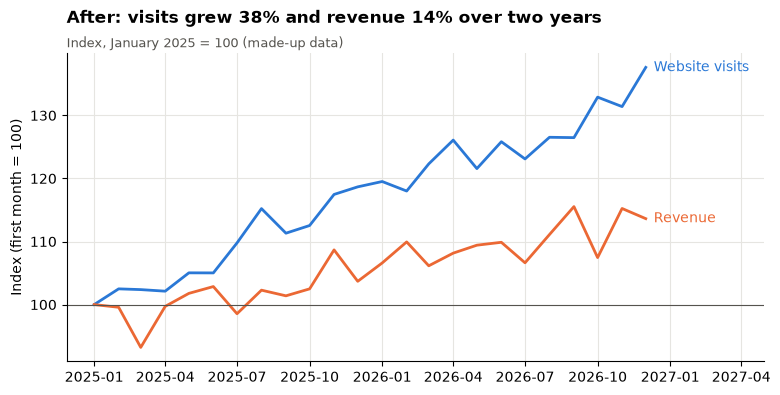

In [17]:
indexed = pd.DataFrame({
    "Website visits": visits / visits.iloc[0] * 100,
    "Revenue": revenue / revenue.iloc[0] * 100,
})

fig, ax = plt.subplots(figsize=(9, 4))
for name, colour in [("Website visits", BLUE), ("Revenue", ORANGE)]:
    ax.plot(indexed.index, indexed[name], color=colour, linewidth=2)
    ax.text(indexed.index[-1], indexed[name].iloc[-1], f"  {name}", color=colour, va="center")
ax.axhline(100, color=INK, linewidth=0.8)
ax.set_xlim(right=indexed.index[-1].to_pydatetime() + datetime.timedelta(days=150))
growth_v = indexed["Website visits"].iloc[-1] - 100
growth_r = indexed["Revenue"].iloc[-1] - 100
ax.set_title(f"After: visits grew {growth_v:.0f}% and revenue {growth_r:.0f}% over two years", pad=22)
ax.text(0, 1.02, "Index, January 2025 = 100 (made-up data)", transform=ax.transAxes, fontsize=9, color=INK)
ax.set_ylabel("Index (first month = 100)")
plt.show()

### Misleading chart 3: pictures that grow in two directions

Infographics often show a bigger number as a bigger picture. If the picture's **height and width** both grow with the number, its **area** grows with the square: a value twice as large looks four times as large.

> **Predict, then reveal**
>
> Sales doubled from 100 to 200 (made-up numbers). Look at the left panel first: how many times bigger does the second square **look**?

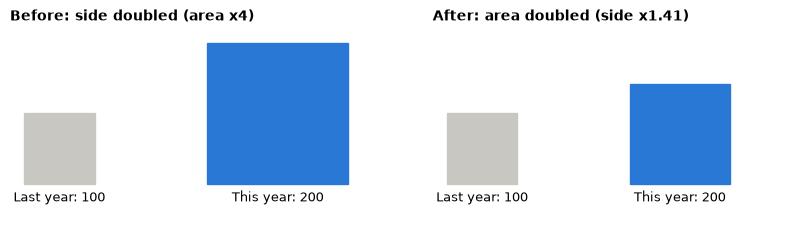

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, sides, title in [
    (ax1, (1.0, 2.0), "Before: side doubled (area x4)"),
    (ax2, (1.0, np.sqrt(2)), "After: area doubled (side x1.41)"),
]:
    ax.add_patch(Rectangle((0, 0), sides[0], sides[0], color=GREY))
    ax.add_patch(Rectangle((2.6, 0), sides[1], sides[1], color=BLUE))
    ax.text(sides[0] / 2, -0.25, "Last year: 100", ha="center", fontsize=9)
    ax.text(2.6 + sides[1] / 2, -0.25, "This year: 200", ha="center", fontsize=9)
    ax.set_xlim(-0.2, 4.8)
    ax.set_ylim(-0.5, 2.2)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=10)
plt.show()

Even the honest version on the right is hard to read, because area is a weak encoding (Part 2). The best rebuild is the simplest: two bars from zero, labelled 100 and 200.

### A checklist of misleading charts

| Trap | What it does | Honest rebuild |
|---|---|---|
| **Truncated bar axis** | Small differences look huge | Bars from zero; or a dot plot with a labelled, zoomed axis |
| **Dual axes** | The author's choice of two scales creates any story | Index both series to 100, or draw two panels |
| **Area or picture scaling** | Doubling height and width shows ×4 | Bars; if you must use area, scale the area, not the side |
| **Pie with many slices, 3D effects** | Angles and tilted areas are misread | Sorted bar chart |
| **Rainbow colours, spaghetti lines** | Every line shouts; nothing stands out | One highlight colour, grey context, or small multiples |
| **Cherry-picked time window** | The start and end dates create the trend | Show the full period, or explain the window |
| **Missing context or denominator** | "Complaints doubled" from 2 to 4 | Show counts with rates, and a comparison |

> **Check your understanding**
>
> For each, is a non-zero axis acceptable? Explain in one sentence.
>
> 1. A bar chart of tip percentage by day.
> 2. A line chart of daily share price over one month.
> 3. A dot plot of average delivery days by carrier, with the axis labelled.

---

## Part 8: Message titles, annotation and small multiples

A **descriptive title** ("Fuel economy against weight") tells the reader what is on the chart. A **message title** tells them what to **see** ("Heavier cars travel fewer miles per gallon"). Managers read titles first, and sometimes only titles.

Two rules:

1. The message must be **true for the chart as drawn**: the same period and filters. If the data change, re-check the title.
2. Keep the **scope** (period, population, units) in a subtitle or note, so the message stays short.

Before:

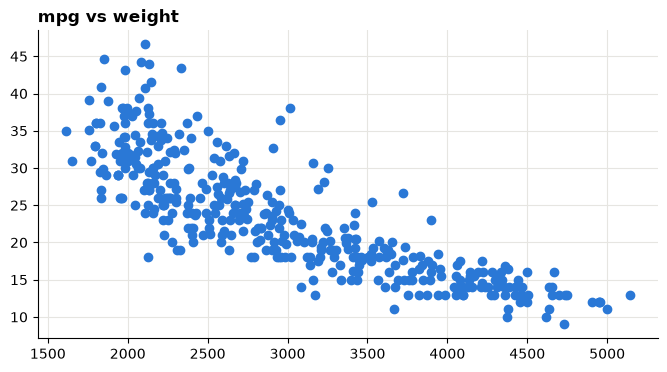

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(cars["weight"], cars["mpg"])
ax.set_title("mpg vs weight")
plt.show()

After: grey points for context, a straight trend line, one annotation that turns the slope into a sentence, and a message title. The code checks the claim before writing it: it only says "heavier cars travel fewer miles" if the correlation is clearly negative.

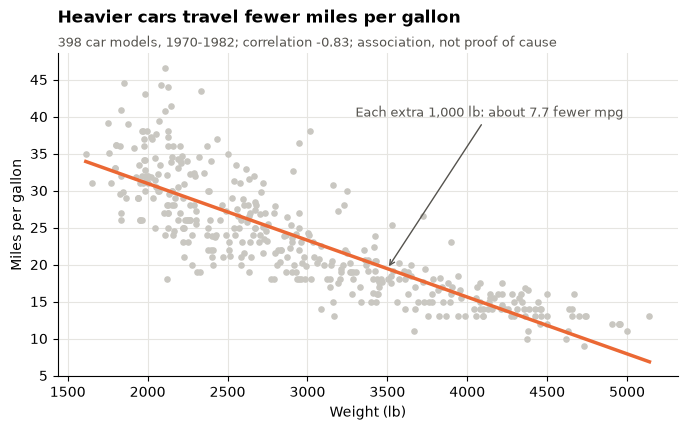

In [20]:
slope, intercept = np.polyfit(cars["weight"], cars["mpg"], 1)
r = cars["weight"].corr(cars["mpg"])
line_x = np.array([cars["weight"].min(), cars["weight"].max()])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(cars["weight"], cars["mpg"], s=14, color=GREY)
ax.plot(line_x, intercept + slope * line_x, color=ORANGE, linewidth=2.5)
ax.annotate(f"Each extra 1,000 lb: about {-slope * 1000:.1f} fewer mpg",
            xy=(3500, intercept + slope * 3500), xytext=(3300, 40), fontsize=9, color=INK,
            arrowprops={"arrowstyle": "->", "color": INK})
ax.set_title("Heavier cars travel fewer miles per gallon" if r < -0.5
             else "Fuel economy and weight are only weakly related", pad=22)
ax.text(0, 1.02, f"398 car models, 1970-1982; correlation {r:.2f}; association, not proof of cause",
        transform=ax.transAxes, fontsize=9, color=INK)
ax.set_xlabel("Weight (lb)")
ax.set_ylabel("Miles per gallon")
plt.show()

**Annotation** is text on the chart that explains one thing at the place it happens: a peak, a policy change, a slope. Use one to three notes per chart.

### Small multiples

When one chart has too many series, draw **many small charts with the same axes**, one per group. Tufte called these **small multiples**. Each panel below shows one origin in blue, with the other cars in grey for context.

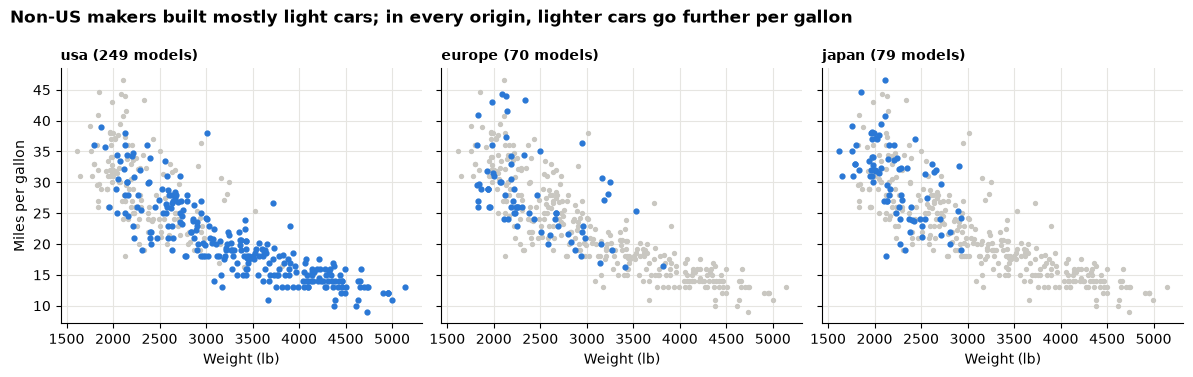

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
for ax, origin in zip(axes, ["usa", "europe", "japan"]):
    ax.scatter(cars["weight"], cars["mpg"], s=8, color=GREY)
    mine = cars[cars["origin"] == origin]
    ax.scatter(mine["weight"], mine["mpg"], s=12, color=BLUE)
    ax.set_title(f"{origin} ({len(mine)} models)", fontsize=10)
    ax.set_xlabel("Weight (lb)")
axes[0].set_ylabel("Miles per gallon")
fig.suptitle("Non-US makers built mostly light cars; in every origin, lighter cars go further per gallon",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

> **Small multiples checklist**
>
> 1. Same axes in every panel (`sharex=True, sharey=True`), unless you say clearly that they differ.
> 2. Panels in a meaningful order (by size, geography or time), not alphabetical by default.
> 3. One highlight colour, the same in every panel.

> **Check your understanding**
>
> Rewrite each descriptive title as a message title. Invent a plausible finding; the point is the form.
>
> 1. "Returns by region, 2025"
> 2. "Average delivery days by carrier"

---

## Part 9: Communicating results: audience, big idea, story

A correct analysis that nobody understands changes nothing.

### Exploratory versus explanatory

| | Exploratory | Explanatory |
|---|---|---|
| **Purpose** | Find out what is in the data | Tell someone what you found and what to do |
| **Audience** | You and your team | A decision-maker |
| **Number of charts** | Many, quick, rough | As few as possible |
| **Titles** | Describe what is plotted | State the message |
| **Style** | Defaults are fine | Clean, highlighted, annotated, with a scope note |

Most charts you make while exploring should **never** reach a manager. The skill is choosing the few that matter and redrawing them so the message is impossible to miss.

### Audience and the decision

Before drawing anything, answer three questions:

1. **Who** is the audience, and what do they already know?
2. **What decision** do they face, and by when?
3. **What do you want them to do** or believe after seeing your work?

| Audience | What they need | What to leave out |
|---|---|---|
| Executive | The recommendation, two or three numbers, the main risk | Method details, every breakdown |
| Manager of one area | Their area against the rest, the trend, what to check next | Other areas' detail |
| Analyst colleague | Definitions, data checks, code | Nothing; they need the working |

### The big idea

Before building any chart, write your main message as **one sentence** that states your **point of view**, says **what is at stake**, and is written for **your audience**.

> *Example:* "Cars from non-US makers were far more economical through the 1970s, so a fuel-price rise would hurt the US makers' customers most; the US makers should prioritise lighter models."

If you cannot write the sentence, you are not ready to present. Keep analysing.

### Situation, complication, resolution

A short business story has three parts:

| Part | Question it answers | Example (car makers, 1970s) |
|---|---|---|
| **Situation** | What is true and agreed? | US makers sell the most models |
| **Complication** | What problem does the data reveal? | Their cars average far fewer miles per gallon, mostly because they are heavier |
| **Resolution** | What should we do? | Develop lighter models first, and track average weight and mpg each model year |

The situation is short, because the audience usually knows it. The complication is why they are listening. The resolution is your recommendation.

### Message titles

| Descriptive title | Message title |
|---|---|
| Average mpg by maker | The most economical makers are all non-US makers |
| mpg by origin and year | Every origin improved; European cars improved the most |
| Tip % by day | Tip percentages differ by little more than a point between days |

> **Check your understanding**
>
> Write a situation, complication and resolution, one sentence each, for the small-multiples chart at the end of Part 8. Which sentence needs evidence that the chart does not contain?

---

## Part 10: The Challenger case

On **28 January 1986** the space shuttle *Challenger* broke apart shortly after launch, killing all seven crew. The cause was the failure of rubber **O-ring seals** in a booster rocket, which had stiffened in the cold. The air temperature at launch was about **36°F (2°C)**, far colder than any earlier flight.

The evening before, engineers at the contractor Morton Thiokol warned about the cold and recommended not launching below the coldest temperature previously flown. In a teleconference their recommendation was challenged, managers reversed it, and the launch went ahead.

The data on earlier flights are small enough to type in. Each row is one of the **23 flights before Challenger** for which the boosters were recovered.

| Column | Meaning |
|---|---|
| `flight` | Order of the flight in the data |
| `temp_f` | Air temperature at launch, °F |
| `damaged_orings` | Number of the six field-joint O-rings showing thermal distress (erosion or blow-by) |

> **Data source**
>
> UCI Machine Learning Repository, *Challenger USA Space Shuttle O-Ring* dataset (erosion or blow-by version), based on Draper (1995) and Dalal, Fowlkes and Hoadley (1989). Public data; the 23 rows are typed in below so no download is needed.

In [22]:
challenger = pd.DataFrame({
    "flight": range(1, 24),
    "temp_f": [66, 70, 69, 68, 67, 72, 73, 70, 57, 63, 70, 78,
               67, 53, 67, 75, 70, 81, 76, 79, 75, 76, 58],
    "damaged_orings": [0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0,
                       0, 2, 0, 0, 0, 0, 0, 0, 2, 0, 1],
})
CHALLENGER_TEMP_F = 36
print("Flights:", len(challenger), "| flights with damage:", int((challenger["damaged_orings"] > 0).sum()))
print("Coldest earlier launch:", challenger["temp_f"].min(), "°F | Challenger launch: about", CHALLENGER_TEMP_F, "°F")

Flights: 23 | flights with damage: 7
Coldest earlier launch: 53 °F | Challenger launch: about 36 °F


### View 1: only the flights with damage

Much of the discussion before the launch looked at the flights where O-rings had been **damaged**.

> **Predict, then reveal**
>
> The next chart shows only the damaged flights: temperature along the bottom, number of damaged O-rings up the side. Will you see a clear link between temperature and damage?

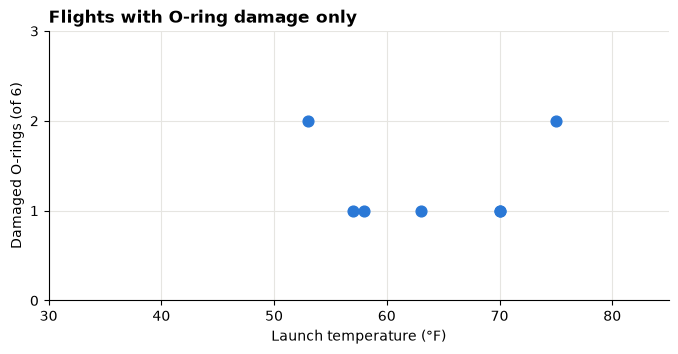

In [23]:
damaged = challenger[challenger["damaged_orings"] > 0]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(damaged["temp_f"], damaged["damaged_orings"], s=60, color=BLUE)
ax.set_xlim(30, 85)
ax.set_ylim(0, 3)
ax.set_yticks([0, 1, 2, 3])
ax.set_title("Flights with O-ring damage only")
ax.set_xlabel("Launch temperature (°F)")
ax.set_ylabel("Damaged O-rings (of 6)")
plt.show()

Damage appears at cool **and** warm temperatures. Looked at this way, temperature does not seem to matter much.

### View 2: all 23 flights

> **Predict, then reveal**
>
> Now we add the flights with **no** damage. Where on the temperature axis do you expect them to sit?

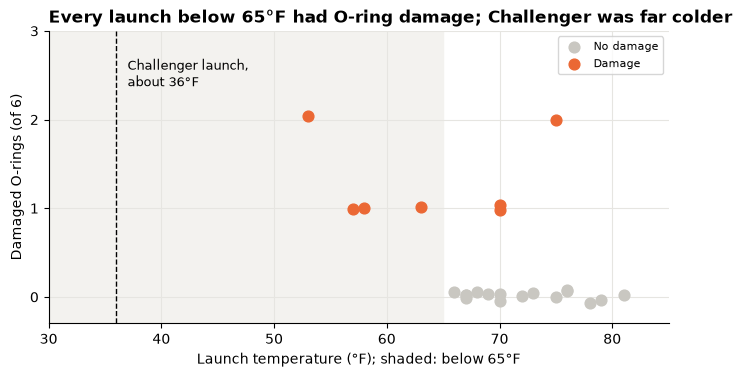

,flights,flights_with_damage,share_with_damage
band,,,
65°F and above,19,3,16%
below 65°F,4,4,100%


In [24]:
rng = np.random.default_rng(seed=14)
jitter = rng.uniform(-0.08, 0.08, len(challenger))   # separates flights with identical values
had_damage = challenger["damaged_orings"] > 0
cold = challenger["temp_f"] < 65

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(challenger.loc[~had_damage, "temp_f"], challenger.loc[~had_damage, "damaged_orings"] + jitter[~had_damage],
           s=60, color=GREY, label="No damage")
ax.scatter(challenger.loc[had_damage, "temp_f"], challenger.loc[had_damage, "damaged_orings"] + jitter[had_damage],
           s=60, color=ORANGE, label="Damage")
ax.axvline(CHALLENGER_TEMP_F, color="black", linestyle="--", linewidth=1)
ax.text(CHALLENGER_TEMP_F + 1, 2.7, "Challenger launch,\nabout 36°F", fontsize=9, va="top")
ax.axvspan(30, 65, color="#f3f2ef", zorder=0)
ax.set_xlim(30, 85)
ax.set_ylim(-0.3, 3)
ax.set_yticks([0, 1, 2, 3])
all_cold_damaged = bool(had_damage[cold].all())
ax.set_title("Every launch below 65°F had O-ring damage; Challenger was far colder"
             if all_cold_damaged else "O-ring damage against launch temperature, all flights")
ax.set_xlabel("Launch temperature (°F); shaded: below 65°F")
ax.set_ylabel("Damaged O-rings (of 6)")
ax.legend(fontsize=8, loc="upper right")
plt.show()

bands = challenger.assign(band=np.where(cold, "below 65°F", "65°F and above"), damage=had_damage)
bands.groupby("band").agg(flights=("flight", "count"), flights_with_damage=("damage", "sum"),
                          share_with_damage=("damage", "mean")).assign(
    share_with_damage=lambda t: t["share_with_damage"].map("{:.0%}".format))

Read the chart and table above together:

1. The flights with **no damage** were almost all **warm** launches. Leaving them out removed the evidence that warm launches were safer than cold ones.
2. In the shaded band below 65°F, read the table: what share of flights had damage, compared with warmer launches?
3. The dashed line is far to the left of **every** earlier flight. Challenger launched well outside all experience, so no chart of earlier flights could show what would happen at 36°F. That itself is the warning.

The lesson for analysts: **the rows you leave out can change the answer.** The zeros were the comparison group.

> **Two views of the lesson**
>
> Edward Tufte argued in *Visual Explanations* (1997) that the charts prepared before and after the accident failed to show the link between temperature and damage clearly, and that a simple scatter of all flights would have. Others, including some of the Thiokol engineers (Robison, Boisjoly, Hoeker and Young, 2002) and the sociologist Diane Vaughan (*The Challenger Launch Decision*, 1996), point out that the engineers **did** argue that cold was the danger, under time pressure, and that the decision was shaped by schedule, organisational culture and a habit of accepting earlier damage as normal. Both lead to the same lesson: **when the stakes are high, show the full comparison so the risk is impossible to miss, and know that a good chart is necessary but not enough.**

> **Check your understanding**
>
> Write a message title for the "damaged flights only" chart that would have been **honest** about what it can and cannot show.

---

## Part 11: Dashboards and KPIs

A **dashboard** is a small set of views on one page that answers a recurring question for one audience. This afternoon you build one in Tableau; the principles are the same in any tool.

| Principle | What it means in practice |
|---|---|
| **Start from the decision** | One question for one audience. A dashboard that answers everything answers nothing |
| **Layout hierarchy** | Readers start at the **top left**. Put the headline numbers and main message there; detail below and to the right |
| **3–5 views at most** | Each view earns its place by answering part of the question |
| **KPI tiles** | A few headline numbers, each with a **comparison** (vs last period, vs target), so the reader knows whether it is good |
| **Consistent colours** | If orange means "needs attention", use it for nothing else, in every view |
| **Filters and actions** | One control that changes every view (in Tableau: a filter or a dashboard action) |
| **Scope and source note** | Period, units, filters, data source and known limits, small but always on the page |
| **Accessibility** | Colour-blind-safe colours, enough contrast, and never colour alone |

### What makes a good KPI?

A **KPI** (key performance indicator) is a metric tied to a goal. A good one is **defined** (everyone computes it the same way), **comparable** (over time or against a target), **actionable** (someone can change it) and **hard to game**. When a measure becomes a target, people can improve the number without improving the business (Goodhart's law), so pair KPIs that keep each other honest, such as sales with profit ratio.

### Ratio of sums versus mean of ratios

Many KPIs are **ratios**: tips ÷ bills, profit ÷ sales, conversions ÷ visits. When you combine groups, there are two tempting ways to get the overall ratio:

- **Ratio of sums:** add up the numerators, add up the denominators, then divide.
- **Mean of ratios:** compute each group's ratio, then average them.

> **Predict, then reveal**
>
> Store A sold 10,000 with a profit of 1,000; a small kiosk B sold 100 with a profit of 50. What is the company's overall profit ratio? Closer to A's ratio, or to the simple average of the two ratios?

In [25]:
stores = pd.DataFrame({"sales": [10_000, 100], "profit": [1_000, 50]}, index=["A", "B"])
stores["profit_ratio"] = stores["profit"] / stores["sales"]
print(stores)
print()
print("Mean of the two ratios:", f"{stores['profit_ratio'].mean():.1%}")
print("Ratio of the sums:     ", f"{stores['profit'].sum() / stores['sales'].sum():.1%}")

   sales  profit  profit_ratio
A  10000    1000          0.10
B    100      50          0.50

Mean of the two ratios: 30.0%
Ratio of the sums:      10.4%


The kiosk's high ratio counts as much as the big store's in the simple mean, although it sold a hundred times less. The **ratio of sums** is what the company actually earned per unit of sales. It equals the average of the store ratios **weighted** by each store's share of sales.

The same choice appears in the tips data. "The tip percentage" could mean either number below:

In [26]:
per_bill_pct = 100 * tips["tip"] / tips["total_bill"]
print(f"Mean of each bill's tip %:            {per_bill_pct.mean():.2f}%")
print(f"Total tips / total bills (ratio of sums): {100 * tips['tip'].sum() / tips['total_bill'].sum():.2f}%")
print(f"Largest single-bill tip %:             {per_bill_pct.max():.1f}% on a bill of "
      f"{tips.loc[per_bill_pct.idxmax(), 'total_bill']:.2f} dollars")

Mean of each bill's tip %:            16.08%
Total tips / total bills (ratio of sums): 15.15%
Largest single-bill tip %:             71.0% on a bill of 7.25 dollars


The two answers in the output above differ because small bills tend to leave a higher **percentage** tip, and in the mean of ratios each small bill gets the same vote as a large one. Neither number is wrong, but they answer different questions:

| Question | Use |
|---|---|
| "Of all the money customers spent, what share went to tips?" (server income, a KPI) | **Ratio of sums** |
| "How generous is a typical table?" | Mean (or median) of each bill's ratio, labelled as such |

> **Totals first, then divide**
>
> For a KPI tile, compute the ratio from totals. In Tableau this is `SUM([Tip]) / SUM([Total Bill])`; you will write it this afternoon.

> **Check your understanding**
>
> A website reports a conversion rate for each of 30 days. Your manager wants "the conversion rate for the month". What do you calculate, and when would the simple average of the 30 daily rates give the same answer?

---

## Part 12: Marketing analytics

Marketing teams spend money to bring customers in and must show what that money achieved. Most of their KPIs come from one picture: the **funnel**.

| Stage | One unit is… | Rate to the next stage |
|---|---|---|
| **Impressions** | One time an ad was shown | **CTR** (click-through rate) = clicks ÷ impressions |
| **Clicks** | One click on an ad | Landing rate = sessions ÷ clicks |
| **Sessions** | One visit to the website | **Conversion rate** = orders ÷ sessions |
| **Orders** | One purchase | |

And the money KPIs:

| KPI | Formula | Read it as | Better when |
|---|---|---|---|
| **CPC** (cost per click) | spend ÷ clicks | paid per click | lower |
| **CPA** (cost per acquisition) | spend ÷ orders | paid per purchase | lower |
| **ROAS** (return on ad spend) | revenue ÷ spend | revenue per unit of spend | higher |
| **AOV** (average order value) | revenue ÷ orders | revenue per purchase | higher |

Every one is a **ratio of sums** over the period and group you report.

> **About the data**
>
> The next cell **generates** a small **synthetic** funnel: four advertising channels over twelve weeks. It describes no real company or platform. Money is in neutral **currency units**. The random generator is seeded, so the numbers are the same every run.

In [27]:
rng = np.random.default_rng(300)  # fixed seed: the synthetic data are the same every run

# Assumed weekly behaviour of each channel (synthetic): spend, impressions per unit of spend,
# click-through rate, share of clicks that reach the site, conversion rate and average order value.
CHANNELS = pd.DataFrame({
    "spend":       [4000, 3000, 2000, 150],
    "impr_per_cu": [100, 300, 750, 800],
    "ctr":         [0.030, 0.008, 0.0015, 0.025],
    "landing":     [0.90, 0.85, 0.80, 0.95],
    "conv":        [0.040, 0.015, 0.008, 0.030],
    "aov":         [60, 50, 55, 65],
}, index=["Search", "Social", "Display", "Email"])

rows = []
for week in range(1, 13):
    for channel, p in CHANNELS.iterrows():
        spend = round(p["spend"] * rng.uniform(0.85, 1.15), 2)
        impressions = int(rng.poisson(spend * p["impr_per_cu"]))
        clicks = int(rng.binomial(impressions, p["ctr"]))
        sessions = int(rng.binomial(clicks, p["landing"]))
        orders = int(rng.binomial(sessions, p["conv"]))
        revenue = round(float(orders * p["aov"] * rng.uniform(0.9, 1.1)), 2)
        rows.append([week, channel, spend, impressions, clicks, sessions, orders, revenue])

funnel = pd.DataFrame(rows, columns=["week", "channel", "spend", "impressions", "clicks",
                                     "sessions", "orders", "revenue"])
print("Rows (weeks x channels):", len(funnel))
funnel.head()

Rows (weeks x channels): 48


,week,channel,spend,impressions,clicks,sessions,orders,revenue
0,1,Search,"4,204.44",420553,12516,11235,470,"27,957.01"
1,1,Social,"3,365.55",1011484,8098,6875,102,"5,246.15"
2,1,Display,"2,226.97",1668279,2509,1967,11,647.04
3,1,Email,139.63,111653,2827,2694,72,"4,714.64"
4,2,Search,"4,228.73",422042,12641,11366,457,"26,813.28"


**Grain:** one row per **week × channel**. A row is not a customer: one person who clicks in three weeks is counted in three rows.

First, the company funnel for the twelve weeks. The stages shrink so fast that a **log scale** is needed to see them all on one chart (each grid step is ten times the one before). A log axis has no zero, so bars would have meaningless lengths: we use dots, read by position.

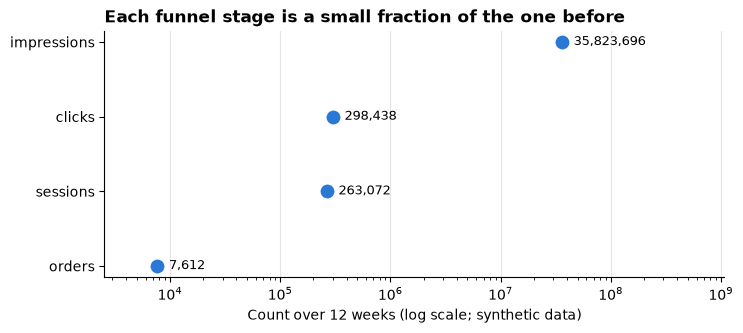

In [28]:
COUNTS = ["spend", "impressions", "clicks", "sessions", "orders", "revenue"]
stages = ["impressions", "clicks", "sessions", "orders"]
company = funnel[stages].sum()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(company, stages, s=80, color=BLUE, zorder=3)   # dots, not bars: a log axis has no zero
ax.set_xscale("log")
ax.invert_yaxis()
for i, value in enumerate(company):
    ax.text(value, i, f"   {value:,.0f}", va="center", fontsize=9)
ax.set_xlim(company.min() / 3, company.max() * 30)
ax.set_title("Each funnel stage is a small fraction of the one before")
ax.set_xlabel("Count over 12 weeks (log scale; synthetic data)")
ax.grid(axis="y", visible=False)
plt.show()

Now the KPIs for each channel. `groupby` adds up the counts first; then we divide the sums. A zero denominator gives "not available" (`NaN`), never 0.

In [29]:
def safe_div(numerator, denominator):
    """numerator / denominator, left blank (NaN, 'not available') wherever the denominator is 0."""
    return numerator / denominator.where(denominator != 0)


def add_kpis(totals):
    """Add funnel KPIs to a table of SUMMED counts (ratios of sums)."""
    t = totals.copy()
    t["CTR %"] = 100 * safe_div(t["clicks"], t["impressions"])
    t["conv %"] = 100 * safe_div(t["orders"], t["sessions"])
    t["CPA"] = safe_div(t["spend"], t["orders"])
    t["ROAS"] = safe_div(t["revenue"], t["spend"])
    t["AOV"] = safe_div(t["revenue"], t["orders"])
    return t


by_channel = add_kpis(funnel.groupby("channel")[COUNTS].sum()).sort_values("spend", ascending=False)
by_channel[["spend", "orders", "revenue", "CTR %", "conv %", "CPA", "ROAS"]]

,spend,orders,revenue,CTR %,conv %,CPA,ROAS
channel,,,,,,,
Search,"48,727.58",5284,"322,961.42",2.99,4.04,9.22,6.63
Social,"37,566.34",1133,"56,152.17",0.79,1.49,33.16,1.49
Display,"24,305.94",170,"9,260.35",0.15,0.79,142.98,0.38
Email,"1,814.09",1025,"64,734.18",2.52,2.95,1.77,35.68


> **Predict, then reveal**
>
> Look at Email's ROAS in the table above. Is Email really many times better at turning money into revenue? Look at its **spend** and **orders** columns before you answer, then run the next cell.

In [30]:
share = by_channel[["spend", "orders"]] / by_channel[["spend", "orders"]].sum() * 100
share.columns = ["% of spend", "% of orders"]
share.join(by_channel[["ROAS"]])

,% of spend,% of orders,ROAS
channel,,,
Search,43.35,69.42,6.63
Social,33.42,14.88,1.49
Display,21.62,2.23,0.38
Email,1.61,13.47,35.68


Email takes a tiny share of the spend but a real share of the orders. Its "spend" covers only a small sending cost; it leaves out building the mailing list, writing the emails and any discounts offered. A ratio with a **tiny denominator** looks extreme. Report Email's ROAS, but do not rank it against paid media as if the costs were comparable.

### Two limits of ROAS

1. **ROAS is not profit.** Revenue of 4 per unit of spend sounds good, but if the product's profit ratio is 20%, each unit of spend earns 0.8 of profit: a loss before any other cost.
2. **ROAS is not causal.** Revenue "attributed" to a channel includes customers who would have bought anyway. Only an experiment (show the ads to a random group, hold out another) measures the **extra** sales the ads caused.

### Attribution: who gets the credit?

Customers often meet several channels before they buy. An **attribution rule** decides which channel gets the credit. Here are five made-up customer journeys:

In [31]:
journeys = pd.DataFrame({
    "customer": ["C1", "C2", "C3", "C4", "C5"],
    "path": [["Social", "Search"], ["Display", "Social", "Email"], ["Search"],
             ["Social", "Email"], ["Display", "Search"]],
})
journeys["first_touch"] = journeys["path"].str[0]
journeys["last_touch"] = journeys["path"].str[-1]

credit = pd.DataFrame({
    "first-touch credit": journeys["first_touch"].value_counts(),
    "last-touch credit": journeys["last_touch"].value_counts(),
}).reindex(["Search", "Social", "Display", "Email"]).fillna(0).astype(int)
print(journeys[["customer", "path"]].to_string(index=False))
credit

customer                     path
      C1         [Social, Search]
      C2 [Display, Social, Email]
      C3                 [Search]
      C4          [Social, Email]
      C5        [Display, Search]


,first-touch credit,last-touch credit
Search,1,3
Social,2,0
Display,2,0
Email,0,2


The same five purchases, two rules, two different "best" channels. **Last-touch** favours channels that close the sale (search, email); **first-touch** favours channels that introduce people (social, display). Neither rule is the truth: each is a convention. When a report says "Search drove 40% of sales", ask **which rule** and remember that a rule is not an experiment.

### Segmentation

**Segmentation** splits customers into groups that behave differently, so each group can get a different offer. A useful segment is large enough to matter, different in a way you can measure, and reachable. A first look with the tips data, segmenting bills by **party size**:

In [32]:
segments = tips.assign(party=pd.cut(tips["size"], [0, 1, 2, 4, 6], labels=["1", "2", "3-4", "5-6"]))
seg = segments.groupby("party", observed=True).agg(
    bills=("total_bill", "size"),
    revenue=("total_bill", "sum"),
    tips=("tip", "sum"),
    people=("size", "sum"),
)
seg["% of bills"] = 100 * seg["bills"] / seg["bills"].sum()
seg["% of revenue"] = 100 * seg["revenue"] / seg["revenue"].sum()
seg["spend per person"] = seg["revenue"] / seg["people"]
seg["tip % (sum/sum)"] = 100 * seg["tips"] / seg["revenue"]
seg[["bills", "% of bills", "% of revenue", "spend per person", "tip % (sum/sum)"]]

,bills,% of bills,% of revenue,spend per person,tip % (sum/sum)
party,,,,,
1,4,1.64,0.60,7.24,19.85
2,156,63.93,53.15,8.22,15.70
3-4,75,30.74,40.25,7.42,14.51
5-6,9,3.69,6.00,5.91,14.17


Read the output above as a marketer: which segment brings most of the revenue, and which spends most **per person**? Segments differ in **size** and in **value**; a promotion aimed at a small, high-value segment and one aimed at the largest segment are different decisions.

### Customer lifetime value (CLV), the intuition

A customer is worth more than one order. A simple **CLV** estimate multiplies what a customer brings per year by how long they stay:

> **CLV ≈ average order value × orders per year × profit ratio × expected years as a customer**

Compare CLV with what it costs to win a customer (the **CPA** for new customers). If winning a customer costs more than they are ever worth, the campaign destroys value however good its ROAS looks. A worked example with the synthetic funnel's AOV and **assumed** loyalty figures:

In [33]:
aov_all = funnel["revenue"].sum() / funnel["orders"].sum()
cpa_all = funnel["spend"].sum() / funnel["orders"].sum()

# Assumptions (made up for teaching): a 20% profit ratio; loyal customers order more often and stay longer.
PROFIT_RATIO = 0.20
clv = pd.DataFrame({
    "orders per year": [1.0, 4.0],
    "expected years": [1.0, 3.0],
}, index=["one-off buyer", "loyal customer"])
clv["CLV"] = aov_all * clv["orders per year"] * PROFIT_RATIO * clv["expected years"]
clv["CLV / CPA"] = clv["CLV"] / cpa_all

print(f"Average order value (all channels): {aov_all:.2f} currency units")
print(f"Cost per order, used here as the cost of winning a customer: {cpa_all:.2f} currency units")
clv

Average order value (all channels): 59.53 currency units
Cost per order, used here as the cost of winning a customer: 14.77 currency units


,orders per year,expected years,CLV,CLV / CPA
one-off buyer,1.00,1.00,11.91,0.81
loyal customer,4.00,3.00,142.86,9.67


In the output above, compare each row's CLV with the cost per order: a `CLV / CPA` below 1 means the customer is worth less than it cost to win them. The same acquisition cost can be a loss on a one-off buyer and a good investment for a loyal customer. That is why marketers care about **retention**, not only acquisition. The figures are assumptions: a real CLV needs purchase histories, and should be stated with its assumptions.

### A small marketing dashboard

Everything in this lecture comes together on one page: a headline, four KPI tiles with comparisons, three views and a scope note. The comparison is the last six weeks against the first six.

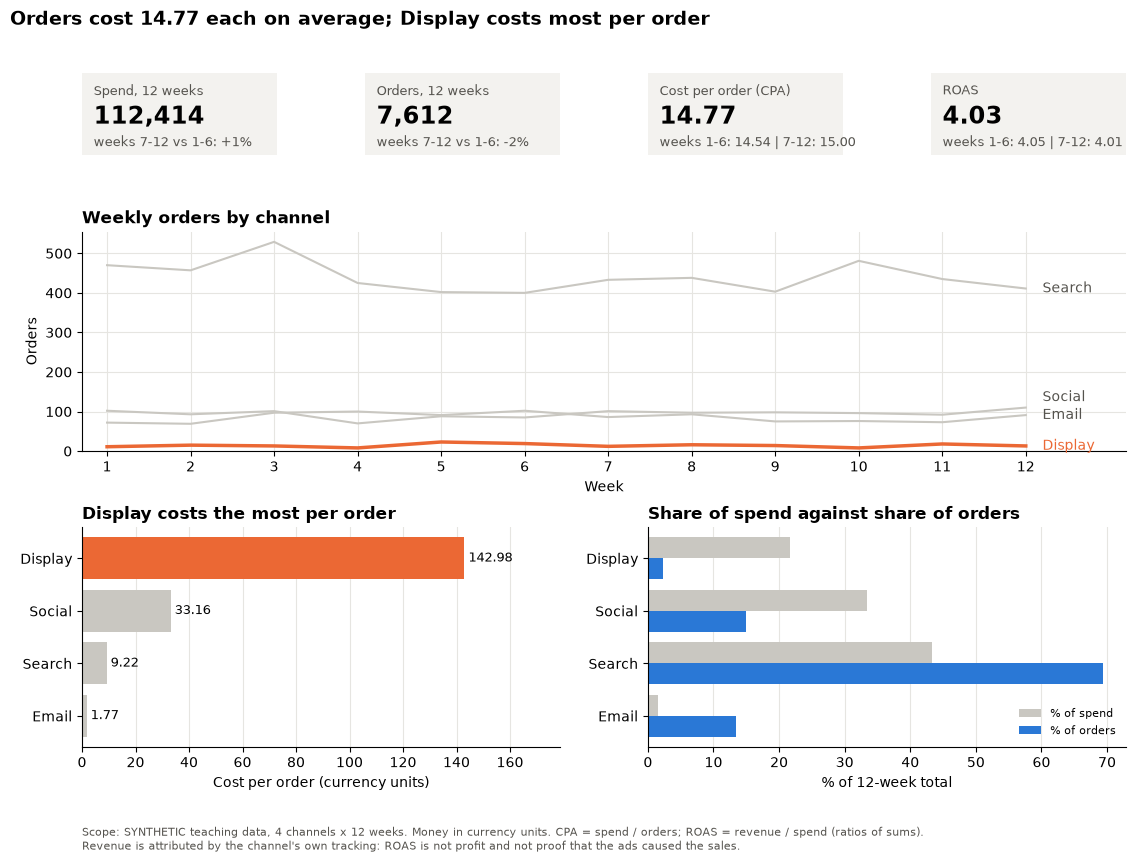

In [34]:
def kpi_tile(ax, label, value, note):
    """A text-only KPI tile: label, big number, comparison."""
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#f3f2ef", zorder=0))
    ax.text(0.06, 0.78, label, transform=ax.transAxes, fontsize=9, color=INK, va="center")
    ax.text(0.06, 0.46, value, transform=ax.transAxes, fontsize=17, fontweight="bold", va="center")
    ax.text(0.06, 0.16, note, transform=ax.transAxes, fontsize=9, color=INK, va="center")


early = add_kpis(funnel[funnel["week"] <= 6][COUNTS].sum().to_frame().T).iloc[0]
late = add_kpis(funnel[funnel["week"] > 6][COUNTS].sum().to_frame().T).iloc[0]
total = add_kpis(funnel[COUNTS].sum().to_frame().T).iloc[0]
weekly = funnel.pivot_table(index="week", columns="channel", values="orders", aggfunc="sum")
cpa = by_channel["CPA"].sort_values()
worst = cpa.index[-1]

fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(4, 4, height_ratios=[0.75, 2.0, 2.0, 0.3], hspace=0.55, wspace=0.45)
kpi_tile(fig.add_subplot(gs[0, 0]), "Spend, 12 weeks", f"{total['spend']:,.0f}",
         f"weeks 7-12 vs 1-6: {late['spend'] / early['spend'] - 1:+.0%}")
kpi_tile(fig.add_subplot(gs[0, 1]), "Orders, 12 weeks", f"{total['orders']:,.0f}",
         f"weeks 7-12 vs 1-6: {late['orders'] / early['orders'] - 1:+.0%}")
kpi_tile(fig.add_subplot(gs[0, 2]), "Cost per order (CPA)", f"{total['CPA']:.2f}",
         f"weeks 1-6: {early['CPA']:.2f} | 7-12: {late['CPA']:.2f}")
kpi_tile(fig.add_subplot(gs[0, 3]), "ROAS", f"{total['ROAS']:.2f}",
         f"weeks 1-6: {early['ROAS']:.2f} | 7-12: {late['ROAS']:.2f}")

ax = fig.add_subplot(gs[1, :])
label_y = weekly.iloc[-1].sort_values()
for k in range(1, len(label_y)):   # keep end labels at least 45 orders apart so they do not overlap
    label_y.iloc[k] = max(label_y.iloc[k], label_y.iloc[k - 1] + 45)
for channel in weekly.columns:
    colour = ORANGE if channel == worst else GREY
    ax.plot(weekly.index, weekly[channel], color=colour, linewidth=2.5 if channel == worst else 1.5)
    ax.text(12.2, label_y[channel], channel, color=colour if channel == worst else INK, va="center")
ax.set_xlim(0.7, 13.2)
ax.set_ylim(0, None)
ax.set_xticks(range(1, 13))
ax.set_title("Weekly orders by channel")
ax.set_xlabel("Week")
ax.set_ylabel("Orders")

ax = fig.add_subplot(gs[2, :2])
ax.barh(cpa.index, cpa, color=[ORANGE if c == worst else GREY for c in cpa.index])
for i, value in enumerate(cpa):
    ax.text(value, i, f" {value:.2f}", va="center", fontsize=9)
ax.set_xlim(0, cpa.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title(f"{worst} costs the most per order")
ax.set_xlabel("Cost per order (currency units)")

ax = fig.add_subplot(gs[2, 2:])
share_plot = share.loc[cpa.index]
y = np.arange(len(share_plot))
ax.barh(y + 0.2, share_plot["% of spend"], height=0.4, color=GREY, label="% of spend")
ax.barh(y - 0.2, share_plot["% of orders"], height=0.4, color=BLUE, label="% of orders")
ax.set_yticks(y, share_plot.index)
ax.grid(axis="y", visible=False)
ax.set_title("Share of spend against share of orders")
ax.set_xlabel("% of 12-week total")
ax.legend(fontsize=8, frameon=False, loc="lower right")

note = fig.add_subplot(gs[3, :])
note.axis("off")
note.text(0, 0.5, "Scope: SYNTHETIC teaching data, 4 channels x 12 weeks. Money in currency units. CPA = spend / orders; "
          "ROAS = revenue / spend (ratios of sums).\nRevenue is attributed by the channel's own tracking: "
          "ROAS is not profit and not proof that the ads caused the sales.",
          fontsize=8, color=INK, va="center", transform=note.transAxes)
fig.suptitle(f"Orders cost {total['CPA']:.2f} each on average; {worst} costs most per order",
             x=0.02, y=0.97, ha="left", fontsize=14, fontweight="bold")
fig.subplots_adjust(left=0.08, right=0.95, top=0.9, bottom=0.03)
plt.show()

Check the dashboard above against the principles in Part 11:

1. **Hierarchy:** the headline and four tiles answer "how did the twelve weeks go?" before any chart.
2. **Views:** three charts, each answering one part of the question.
3. **Colour:** grey means "for comparison"; orange appears only for the channel that needs attention.
4. **Not colour alone:** channels are labelled at the line ends and on the bars.
5. **Scope note:** it says the data are synthetic, gives units and formulas, and states the main limit of ROAS.

> **Check your understanding**
>
> 1. A campaign had 200,000 impressions, 2,000 clicks, 1,600 sessions, 40 orders, spend of 1,000 and revenue of 3,200. Work out its CTR, conversion rate, CPA and ROAS by hand.
> 2. A dashboard shows six KPI tiles and nine charts, coloured red for "below target" and green for "above target". Name three changes you would make.

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Task first | Compare → bars; distribution → histogram; relationship → scatter; time → line |
| Encodings | Position and length are read best; angle, area and colour worse |
| Pre-attentive, data-ink, Gestalt | One highlight against grey; remove what carries no data; place side by side what must be compared |
| Colour | Categorical, sequential or diverging by the data; colour-blind safe; never colour alone |
| Honest charts | Bars from zero; no dual axes (index instead); scale areas, not sides; show the full window |
| Communication | Audience and decision first; one big idea; situation, complication, resolution; message titles |
| Challenger | The rows you leave out can change the answer |
| Dashboards | One decision, 3–5 views, KPI tiles with comparisons, scope note; ratio KPIs as ratio of sums |
| Marketing | Funnel rates and CPA/ROAS are ratios of sums; ROAS is not profit or causation; attribution is a convention; CLV against CPA |

---

## Closing quiz

Answer in your own words, alone, in two or three minutes per question. We discuss the answers before lunch.

1. Name the five chart tasks and a good first chart for each.
2. Why is a pie chart with ten slices hard to read? Use the word "encoding" in your answer.
3. What is a pre-attentive attribute? Give two examples and one way to misuse them.
4. You show profit change by department, where some departments improved and some got worse. Which palette type do you use, and where must its neutral colour sit?
5. Why must a bar chart start at zero when a line chart need not?
6. A colleague's dual-axis chart shows revenue and visits "crossing" in March. What do you tell them, and what would you draw instead?
7. What is the difference between an exploratory and an explanatory chart? Give one change you make when turning one into the other.
8. In the Challenger data, what went wrong when only the damaged flights were plotted?
9. Three branches have conversion rates of 10%, 20% and 30% on 1,000, 100 and 10 visits. Is the overall rate 20%? Explain.
10. Give one reason why the channel with the highest ROAS may not deserve more budget.

---

## This afternoon

1. **Theory:** [Building dashboards in Tableau](D2_lecture_tableau_dashboards.md): from data to sheets to an interactive dashboard, and the Assignment 1 briefing.
2. **Lab:** [Applied Lab 2: Dashboard creation](D2_lab_lab2_dashboard.md) (graded, 3%), then start [Assignment 1](D2_assignment1_tips_report.md).